# Term variance

Run all cells with the `silscore` environment; the included caches are sufficient.

Generated from [nb6_term_variance.py](nb6_term_variance.py).

In [1]:
"""Variances of the three score terms across guide sets.

Read the aggregate variance cache.
"""
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from IPython.display import Image, display
import numpy as np


def _resolve_root() -> Path:
    file_name = globals().get("__file__")
    if file_name:
        return Path(file_name).resolve().parents[1]
    cwd = Path.cwd().resolve()
    if (cwd / "data" / "cache").is_dir():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data" / "cache").is_dir():
        return cwd.parent
    raise RuntimeError("cannot resolve Silscore root from __file__ or cwd")


ROOT = _resolve_root()
CACHE = ROOT / "data" / "cache" / "term_variance.npz"
OUT = ROOT / "output" / "figures"
DATASETS = ("huesken", "mix", "taka")
DATASET_LABELS = ("Huesken", "Mixset", "Katoh–Suzuki")
COMPONENTS = ("local_stability", "global_stability", "nucleotide_identity")
COMPONENT_LABELS = ("Local stability", "Global stability", "Nucleotide identity")
COMPONENT_COLORS = ("#245AA5", "#777777", "#D58B32")
EXPECTED_GUIDES = np.array([249, 472, 702])
FIG_W, FIG_H = 5.586, 2.20
FS_TICK, FS_LABEL, FS_TITLE = 8.0, 9.0, 8.0
PAPER_STYLE = {
    "font.family": "DejaVu Sans",
    "font.size": FS_TICK,
    "axes.linewidth": 0.6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


def read_cache() -> dict[str, np.ndarray | float | str]:
    """Load and validate the aggregate arrays used by the figure and table."""
    if not CACHE.exists():
        raise FileNotFoundError(f"missing {CACHE}")
    required = {
        "datasets", "components", "n_guides", "means", "variances",
        "variance_shares", "covariance", "score_variance",
        "sum_term_variances", "covariance_total",
        "variance_ddof", "model_sha256", "input_sha256",
        "reconstruction_max_abs", "score_offset",
    }
    with np.load(CACHE, allow_pickle=False) as archive:
        missing = sorted(required.difference(archive.files))
        if missing:
            raise ValueError(f"term variance cache is missing arrays: {missing}")
        data = {name: archive[name].copy() for name in required}

    if tuple(data["datasets"].astype(str)) != DATASETS:
        raise ValueError("unexpected dataset order in term variance cache")
    if tuple(data["components"].astype(str)) != COMPONENTS:
        raise ValueError("unexpected component order in term variance cache")
    shapes = {
        "n_guides": (3,), "means": (3, 3), "variances": (3, 3),
        "variance_shares": (3, 3), "covariance": (3, 3, 3),
        "score_variance": (3,), "sum_term_variances": (3,),
        "covariance_total": (3,), "input_sha256": (3,),
        "reconstruction_max_abs": (3,),
    }
    for name, shape in shapes.items():
        if data[name].shape != shape:
            raise ValueError(f"{name} has shape {data[name].shape}; expected {shape}")
        if name != "input_sha256" and not np.isfinite(data[name]).all():
            raise ValueError(f"nonfinite {name}")
    if not np.array_equal(data["n_guides"], EXPECTED_GUIDES):
        raise ValueError("unexpected guide counts in term variance cache")
    if np.asarray(data["variance_ddof"]).shape != () or int(data["variance_ddof"]) != 0:
        raise ValueError("expected descriptive variances with ddof=0")
    if not np.allclose(data["variance_shares"].sum(axis=1), 1.0, atol=1e-8):
        raise ValueError("variance shares must sum to one for each dataset")
    return data


def draw_figure(data: dict[str, np.ndarray | float | str]) -> plt.Figure:
    """Draw stacked component variance shares for each dataset."""
    shares = np.asarray(data["variance_shares"])
    with plt.rc_context(PAPER_STYLE):
        fig, ax_share = plt.subplots(figsize=(FIG_W, FIG_H), dpi=300)
        fig.subplots_adjust(left=0.15, right=0.98, bottom=0.18, top=0.72)
        x = np.arange(len(DATASET_LABELS))
        bottom = np.zeros(3)
        for component_index, label in enumerate(COMPONENT_LABELS):
            values = 100.0 * shares[:, component_index]
            ax_share.bar(
                x, values, bottom=bottom, width=0.62, color=COMPONENT_COLORS[component_index],
                edgecolor="white", linewidth=0.5, label=label,
            )
            for index, value in enumerate(values):
                ax_share.text(index, bottom[index] + value / 2, f"{value:.1f}",
                              ha="center", va="center", color="white", fontsize=7.0)
            bottom += values
        ax_share.set_ylim(0, 100)
        ax_share.set_yticks((0, 50, 100), ("0", "50", "100"))
        ax_share.set_ylabel("Term variance\nshare (%)", fontsize=FS_LABEL, labelpad=4)
        ax_share.set_xticks(x, DATASET_LABELS)
        ax_share.tick_params(labelsize=FS_TICK, length=2.5, width=0.6, pad=3)
        ax_share.set_title("Variance shares", loc="left", fontsize=FS_TITLE, pad=5)
        ax_share.spines[["top", "right"]].set_visible(False)
        ax_share.legend(loc="lower center", bbox_to_anchor=(0.5, 1.22),
                        ncol=3, frameon=False, fontsize=7.0,
                        handlelength=1.4, columnspacing=1.2)

        return fig


def draw_covariance_figure(data: dict[str, np.ndarray | float | str]) -> plt.Figure:
    """Draw the cached covariance matrices in global, local, identity order."""
    covariance = np.asarray(data["covariance"])
    np.testing.assert_allclose(covariance, covariance.swapaxes(1, 2))
    np.testing.assert_allclose(np.diagonal(covariance, axis1=1, axis2=2),
                               data["variances"])
    np.testing.assert_allclose(covariance.sum(axis=(1, 2)), data["score_variance"])

    order = (1, 0, 2)  # Display the terms in manuscript order: global, local, identity.
    values = 1000 * covariance[:, order, :][:, :, order]
    norm = TwoSlopeNorm(vmin=-values.max(), vcenter=0, vmax=values.max())
    colors = plt.get_cmap("RdBu_r")(np.linspace(0, 1, 257))
    colors[128] = (1, 1, 1, 1)
    cmap = ListedColormap(colors)
    np.testing.assert_array_equal(cmap(norm(0)), (1, 1, 1, 1))
    mask = np.triu(np.ones((3, 3), dtype=bool), k=1)
    labels = ("Global\nstability", "Local\nstability", "Nucleotide\nidentity")
    titles = ("A  Huesken test", "B  Mixset", "C  Katoh–Suzuki")
    style = {"font.family": "DejaVu Sans", "font.size": 8,
             "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": 0.6}
    with plt.rc_context(style):
        width, height = 5.586, 2.0
        side, bottom = 1.20, 0.43
        fig = plt.figure(figsize=(width, height))
        for index in range(3):
            left = 0.72 + index * (side + 0.24)
            ax = fig.add_axes([left / width, bottom / height, side / width, side / height])
            im = ax.pcolormesh(np.arange(-0.5, 3), np.arange(-0.5, 3),
                               np.ma.array(values[index], mask=mask),
                               cmap=cmap, norm=norm, edgecolors="white",
                               linewidth=0.5, antialiased=False)
            ax.set_xlim(-0.5, 2.5)
            ax.set_ylim(2.5, -0.5)
            ax.set_aspect("equal")
            ax.set_xticks(range(3), ("Global", "Local", "Identity"), fontsize=7)
            ax.set_yticks(range(3), labels if index == 0 else ["", "", ""])
            ax.tick_params(length=0, pad=4)
            ax.set_title(titles[index], fontsize=8, pad=6, loc="left")
            for spine in ax.spines.values():
                spine.set_visible(False)
            for row in range(3):
                for col in range(row + 1):
                    value = values[index, row, col]
                    ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                            color="white" if abs(value) > values.max() * 0.6 else "black")
        cax = fig.add_axes([4.98 / width, bottom / height, 0.065 / width, side / height])
        bar = fig.colorbar(im, cax=cax, ticks=[-8, -4, 0, 4, 8])
        bar.set_label("Covariance (score² × 10³)", fontsize=8, labelpad=5)
        bar.ax.tick_params(labelsize=8, width=0.6, length=2.5)
        bar.outline.set_linewidth(0.6)
        return fig


def export_and_display(fig: plt.Figure) -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    with plt.rc_context(PAPER_STYLE):
        for extension in ("png", "pdf"):
            fig.savefig(OUT / f"fig_term_variance.{extension}", facecolor="white", dpi=300)
    plt.close(fig)
    display(Image(filename=str(OUT / "fig_term_variance.png")))


def print_variances(data: dict[str, np.ndarray | float | str]) -> None:
    """Print absolute component variances and their normalized shares."""
    variances = np.asarray(data["variances"])
    shares = np.asarray(data["variance_shares"])
    print("Dataset          Component             Variance (score²)  Share (%)")
    for i, dataset_label in enumerate(DATASET_LABELS):
        for j, component_label in enumerate(COMPONENT_LABELS):
            print(f"{dataset_label:<16} {component_label:<21} {variances[i, j]:>17.8g} {100 * shares[i, j]:>10.1f}")


def print_covariances(data: dict[str, np.ndarray | float | str]) -> None:
    """Print the three pair covariances and variance reconstruction terms."""
    cov = np.asarray(data["covariance"])
    print("Dataset          Cov(local, global)  Cov(local, identity)  Cov(global, identity)  Sum term vars  Covariance total  Score variance")
    for i, label in enumerate(DATASET_LABELS):
        print(
            f"{label:<16} {cov[i, 0, 1]:>18.8g} {cov[i, 0, 2]:>21.8g} "
            f"{cov[i, 1, 2]:>22.8g} {np.asarray(data['sum_term_variances'])[i]:>14.8g} "
            f"{np.asarray(data['covariance_total'])[i]:>17.8g} "
            f"{np.asarray(data['score_variance'])[i]:>14.8g}"
        )

In [2]:
data = read_cache()
print_variances(data)

Dataset          Component             Variance (score²)  Share (%)
Huesken          Local stability            0.0080393443       54.0
Huesken          Global stability           0.0031198964       20.9
Huesken          Nucleotide identity         0.003733088       25.1
Mixset           Local stability            0.0080208867       56.0
Mixset           Global stability           0.0024321554       17.0
Mixset           Nucleotide identity        0.0038630567       27.0
Katoh–Suzuki     Local stability            0.0070699891       51.7
Katoh–Suzuki     Global stability           0.0035703343       26.1
Katoh–Suzuki     Nucleotide identity        0.0030365496       22.2


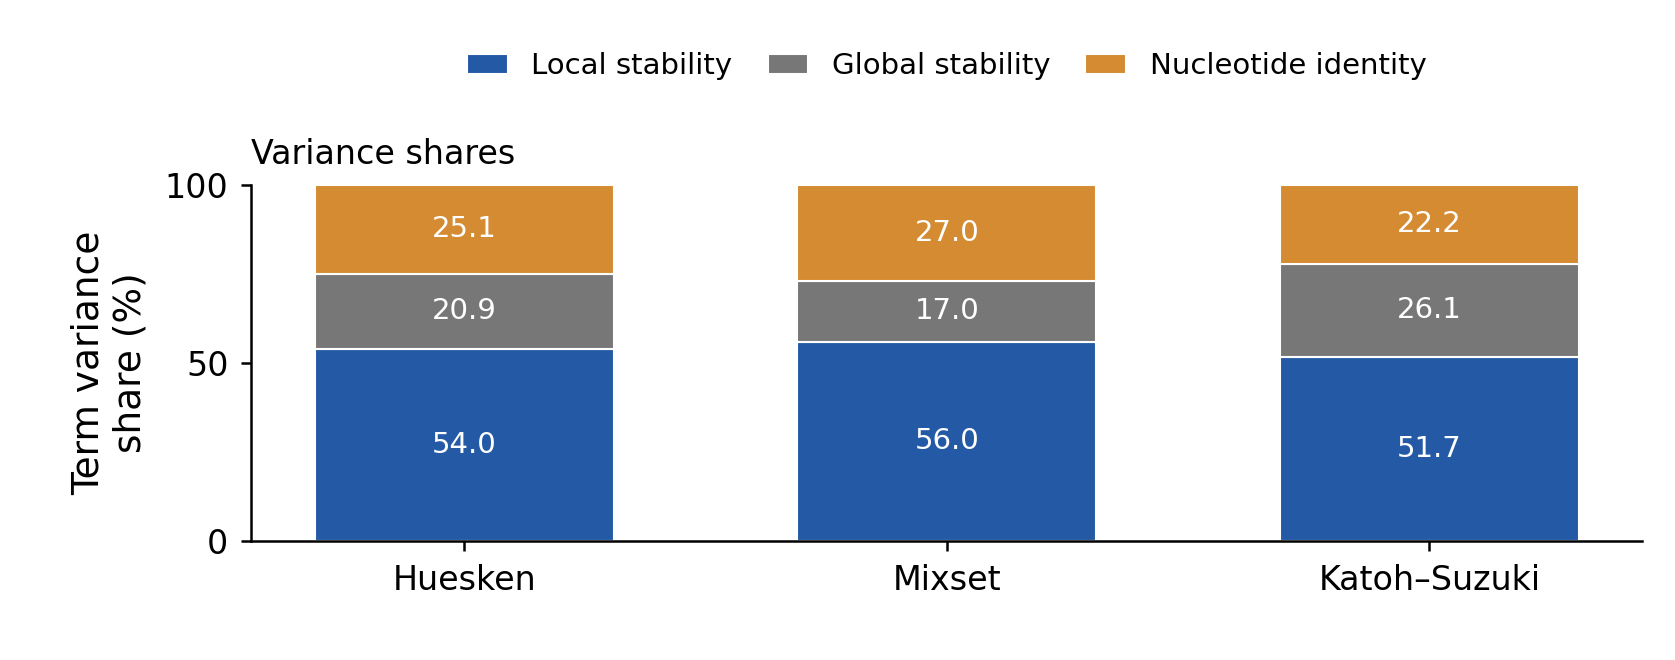

In [3]:
fig = draw_figure(data)
export_and_display(fig)

In [4]:
print_covariances(data)

Dataset          Cov(local, global)  Cov(local, identity)  Cov(global, identity)  Sum term vars  Covariance total  Score variance
Huesken               0.00040912479         7.2373641e-05          0.00030983212    0.014892329      0.0015826611     0.01647499
Mixset                0.00014088624        -4.4013837e-05          0.00079878262    0.014316099      0.0017913101    0.016107409
Katoh–Suzuki          8.7736255e-05        -0.00014406265          0.00058679153    0.013676873      0.0010609303    0.014737803


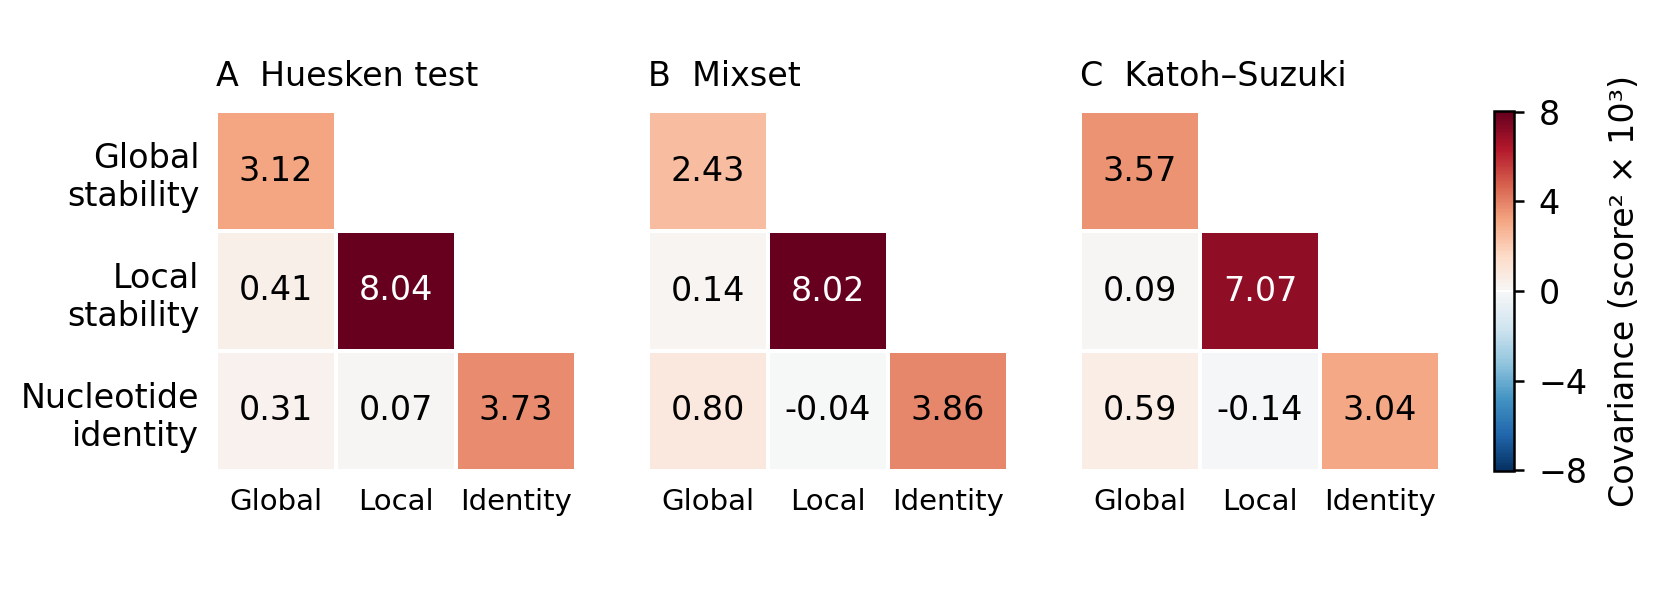

In [5]:
fig_covariance = draw_covariance_figure(data)
OUT.mkdir(parents=True, exist_ok=True)
with plt.rc_context(PAPER_STYLE):
    for extension in ("png", "pdf"):
        fig_covariance.savefig(OUT / f"fig_term_covariance.{extension}",
                               facecolor="white",
                               dpi=fig_covariance.dpi if extension == "pdf" else 300)
plt.close(fig_covariance)
display(Image(filename=str(OUT / "fig_term_covariance.png")))